In [ ]:
import os
import sys
import json
import time
import random
import platform
import subprocess
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)
from scipy.stats import pearsonr

# Install XGBoost only if missing
if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])

import xgboost as xgb

# Reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Mount Google Drive
drive.mount("/content/drive")

# Project paths
BASE_PATH = "/content/drive/MyDrive/Solar_Wind_Project"
ML_PATH = os.path.join(BASE_PATH, "ML")

# Existing prepared datasets
FLAT_PATH = os.path.join(ML_PATH, "data_flat")
ENGINEERED_PATH = os.path.join(ML_PATH, "data_engineered")

# Save all XGBoost outputs directly inside ML/Boosting/
BOOSTING_PATH = os.path.join(ML_PATH, "Boosting")
os.makedirs(BOOSTING_PATH, exist_ok=True)

MODEL_NAME = "02_XGBoost"
RESULT_PREFIX = "xgboost"

# Figures are saved directly in the same folder too
RESULTS_PATH = BOOSTING_PATH
FIGURES_PATH = BOOSTING_PATH

# Fixed evaluation settings
WARMUP_RUNS = 2
INFERENCE_REPEATS = 10
FIGURE_DPI = 300

print("XGBoost version:", xgb.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)
print("Dataset directory:", ML_PATH)
print("Output directory:", RESULTS_PATH)
print("Setup complete.")

Mounted at /content/drive
XGBoost version: 3.4.1
NumPy version: 2.1.3
Pandas version: 2.2.3
Random seed: 42
Dataset directory: /content/drive/MyDrive/Solar_Wind_Project/ML
Output directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting
Setup complete.


In [ ]:
def load_array(folder, filename):
    path = os.path.join(folder, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required dataset file not found: {path}"
        )

    return np.load(path, allow_pickle=False).astype(
        np.float32, copy=False
    )


# Load flattened datasets: 1,008 features per sample
X_train_flat = load_array(FLAT_PATH, "X_train.npy")
X_val_flat = load_array(FLAT_PATH, "X_val.npy")
X_test_flat = load_array(FLAT_PATH, "X_test.npy")

y_train_flat = load_array(FLAT_PATH, "y_train.npy").reshape(-1)
y_val_flat = load_array(FLAT_PATH, "y_val.npy").reshape(-1)
y_test_flat = load_array(FLAT_PATH, "y_test.npy").reshape(-1)


# Load engineered datasets: 112 features per sample
X_train_engineered = load_array(
    ENGINEERED_PATH, "X_train.npy"
)
X_val_engineered = load_array(
    ENGINEERED_PATH, "X_val.npy"
)
X_test_engineered = load_array(
    ENGINEERED_PATH, "X_test.npy"
)

y_train_engineered = load_array(
    ENGINEERED_PATH, "y_train.npy"
).reshape(-1)

y_val_engineered = load_array(
    ENGINEERED_PATH, "y_val.npy"
).reshape(-1)

y_test_engineered = load_array(
    ENGINEERED_PATH, "y_test.npy"
).reshape(-1)


# Verify feature dimensions
assert X_train_flat.shape[1] == 1008
assert X_val_flat.shape[1] == 1008
assert X_test_flat.shape[1] == 1008

assert X_train_engineered.shape[1] == 112
assert X_val_engineered.shape[1] == 112
assert X_test_engineered.shape[1] == 112


# Verify matching sample counts
datasets = [
    ("Flat train", X_train_flat, y_train_flat),
    ("Flat validation", X_val_flat, y_val_flat),
    ("Flat test", X_test_flat, y_test_flat),
    ("Engineered train", X_train_engineered, y_train_engineered),
    ("Engineered validation", X_val_engineered, y_val_engineered),
    ("Engineered test", X_test_engineered, y_test_engineered)
]

for name, X, y in datasets:
    assert len(X) == len(y), f"Sample count mismatch: {name}"


# Verify both representations use exactly the same targets
np.testing.assert_array_equal(
    y_train_flat, y_train_engineered
)
np.testing.assert_array_equal(
    y_val_flat, y_val_engineered
)
np.testing.assert_array_equal(
    y_test_flat, y_test_engineered
)


# Verify all arrays contain finite values
arrays_to_check = {
    "X_train_flat": X_train_flat,
    "X_val_flat": X_val_flat,
    "X_test_flat": X_test_flat,
    "X_train_engineered": X_train_engineered,
    "X_val_engineered": X_val_engineered,
    "X_test_engineered": X_test_engineered,
    "y_train": y_train_flat,
    "y_val": y_val_flat,
    "y_test": y_test_flat
}

for name, array in arrays_to_check.items():
    assert np.isfinite(array).all(), (
        f"NaN or infinity found in {name}"
    )


# Print dataset summary
print("FLAT DATA")
print("Train:", X_train_flat.shape, y_train_flat.shape)
print("Validation:", X_val_flat.shape, y_val_flat.shape)
print("Test:", X_test_flat.shape, y_test_flat.shape)

print("\nENGINEERED DATA")
print(
    "Train:",
    X_train_engineered.shape,
    y_train_engineered.shape
)
print(
    "Validation:",
    X_val_engineered.shape,
    y_val_engineered.shape
)
print(
    "Test:",
    X_test_engineered.shape,
    y_test_engineered.shape
)

print("\nDST TARGET RANGE (nT)")
print(
    "Train:",
    float(y_train_flat.min()),
    "to",
    float(y_train_flat.max())
)
print(
    "Validation:",
    float(y_val_flat.min()),
    "to",
    float(y_val_flat.max())
)
print(
    "Test:",
    float(y_test_flat.min()),
    "to",
    float(y_test_flat.max())
)

print("\nAll data verification checks passed.")

FLAT DATA
Train: (97897, 1008) (97897,)
Validation: (20978, 1008) (20978,)
Test: (20979, 1008) (20979,)

ENGINEERED DATA
Train: (97897, 112) (97897,)
Validation: (20978, 112) (20978,)
Test: (20979, 112) (20979,)

DST TARGET RANGE (nT)
Train: -387.0 to 67.0
Validation: -162.0 to 41.0
Test: -83.0 to 44.0

All data verification checks passed.


In [ ]:
# Fixed XGBoost configuration
# No early stopping; train for exactly 100 boosting rounds.

XGB_PARAMS = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",

    "n_estimators": 100,
    "learning_rate": 0.03,
    "max_depth": 8,
    "min_child_weight": 5,

    "subsample": 0.8,
    "colsample_bytree": 0.8,

    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "gamma": 0.0,

    "tree_method": "hist",
    "device": "cpu",
    "max_bin": 256,

    "n_jobs": -1,
    "random_state": SEED,
    "verbosity": 0
}

# Save the exact configuration
PARAMS_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_parameters.json"
)

with open(PARAMS_PATH, "w") as f:
    json.dump(XGB_PARAMS, f, indent=4)

print("XGBoost configuration:")
for parameter, value in XGB_PARAMS.items():
    print(f"{parameter}: {value}")

print("\nBoosting rounds:", XGB_PARAMS["n_estimators"])
print("Early stopping: Disabled")
print("Training device: CPU")
print("Parameters saved to:", PARAMS_PATH)

XGBoost configuration:
objective: reg:squarederror
eval_metric: rmse
n_estimators: 100
learning_rate: 0.03
max_depth: 8
min_child_weight: 5
subsample: 0.8
colsample_bytree: 0.8
reg_alpha: 0.0
reg_lambda: 1.0
gamma: 0.0
tree_method: hist
device: cpu
max_bin: 256
n_jobs: -1
random_state: 42
verbosity: 0

Boosting rounds: 100
Early stopping: Disabled
Training device: CPU
Parameters saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_parameters.json


In [ ]:
# Cell 4: Train XGBoost on flat features

flat_model = xgb.XGBRegressor(**XGB_PARAMS)

print("Training XGBoost on flat features...")
print("Training samples:", X_train_flat.shape[0])
print("Number of features:", X_train_flat.shape[1])
print("Boosting rounds:", XGB_PARAMS["n_estimators"])
print("Early stopping: Disabled")

start_time = time.perf_counter()

flat_model.fit(
    X_train_flat,
    y_train_flat,
    eval_set=[
        (X_train_flat, y_train_flat),
        (X_val_flat, y_val_flat)
    ],
    verbose=False
)

xgb_flat_training_time = time.perf_counter() - start_time

# Save trained model
FLAT_MODEL_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_flat_model.json"
)

flat_model.save_model(FLAT_MODEL_PATH)

# Save per-round training and validation RMSE
flat_eval_history = flat_model.evals_result()

xgb_flat_training_history = pd.DataFrame({
    "boosting_round": np.arange(
        1, XGB_PARAMS["n_estimators"] + 1
    ),
    "train_rmse": flat_eval_history["validation_0"]["rmse"],
    "validation_rmse": flat_eval_history["validation_1"]["rmse"]
})

HISTORY_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_flat_training_history.csv"
)

xgb_flat_training_history.to_csv(HISTORY_PATH, index=False)

# Report results
print("\nFlat model training completed.")
print(f"Training time: {xgb_flat_training_time:.2f} seconds")
print("Boosting rounds completed:", flat_model.n_estimators)
print(f"Final training RMSE: {xgb_flat_training_history['train_rmse'].iloc[-1]:.4f}")
print(f"Final validation RMSE: {xgb_flat_training_history['validation_rmse'].iloc[-1]:.4f}")
print("Model saved:", FLAT_MODEL_PATH)
print("Training history saved:", HISTORY_PATH)

Training XGBoost on flat features...
Training samples: 97897
Number of features: 1008
Boosting rounds: 100
Early stopping: Disabled

Flat model training completed.
Training time: 204.78 seconds
Boosting rounds completed: 100
Final training RMSE: 10.9475
Final validation RMSE: 8.5107
Model saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_flat_model.json
Training history saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_flat_training_history.csv


In [ ]:
# Cell 5: Train XGBoost on engineered features

engineered_model = xgb.XGBRegressor(**XGB_PARAMS)

print("Training XGBoost on engineered features...")
print("Training samples:", X_train_engineered.shape[0])
print("Number of features:", X_train_engineered.shape[1])
print("Boosting rounds:", XGB_PARAMS["n_estimators"])
print("Early stopping: Disabled")

start_time = time.perf_counter()

engineered_model.fit(
    X_train_engineered,
    y_train_engineered,
    eval_set=[
        (X_train_engineered, y_train_engineered),
        (X_val_engineered, y_val_engineered)
    ],
    verbose=10
)

xgb_engineered_training_time = time.perf_counter() - start_time

# Save trained model
ENGINEERED_MODEL_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_engineered_model.json"
)

engineered_model.save_model(ENGINEERED_MODEL_PATH)

# Save per-round training and validation RMSE
engineered_eval_history = engineered_model.evals_result()

xgb_engineered_training_history = pd.DataFrame({
    "boosting_round": np.arange(
        1, XGB_PARAMS["n_estimators"] + 1
    ),
    "train_rmse": engineered_eval_history["validation_0"]["rmse"],
    "validation_rmse": engineered_eval_history["validation_1"]["rmse"]
})

ENGINEERED_HISTORY_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_engineered_training_history.csv"
)

xgb_engineered_training_history.to_csv(
    ENGINEERED_HISTORY_PATH,
    index=False
)

# Report results
print("\nEngineered-feature model training completed.")
print(f"Training time: {xgb_engineered_training_time:.2f} seconds")
print("Boosting rounds completed:", engineered_model.n_estimators)
print(
    "Final training RMSE:",
    f"{xgb_engineered_training_history['train_rmse'].iloc[-1]:.4f}"
)
print(
    "Final validation RMSE:",
    f"{xgb_engineered_training_history['validation_rmse'].iloc[-1]:.4f}"
)
print("Model saved:", ENGINEERED_MODEL_PATH)
print("Training history saved:", ENGINEERED_HISTORY_PATH)

Training XGBoost on engineered features...
Training samples: 97897
Number of features: 112
Boosting rounds: 100
Early stopping: Disabled
[0]	validation_0-rmse:20.83747	validation_1-rmse:13.06163
[10]	validation_0-rmse:17.78058	validation_1-rmse:11.19053
[20]	validation_0-rmse:15.65100	validation_1-rmse:10.03412
[30]	validation_0-rmse:14.18187	validation_1-rmse:9.32530
[40]	validation_0-rmse:13.12585	validation_1-rmse:8.91307
[50]	validation_0-rmse:12.37010	validation_1-rmse:8.68424
[60]	validation_0-rmse:11.82548	validation_1-rmse:8.55584
[70]	validation_0-rmse:11.41658	validation_1-rmse:8.49375
[80]	validation_0-rmse:11.09504	validation_1-rmse:8.46503
[90]	validation_0-rmse:10.84155	validation_1-rmse:8.45916
[99]	validation_0-rmse:10.63877	validation_1-rmse:8.45277

Engineered-feature model training completed.
Training time: 17.06 seconds
Boosting rounds completed: 100
Final training RMSE: 10.6388
Final validation RMSE: 8.4528
Model saved: /content/drive/MyDrive/Solar_Wind_Project/ML/

In [ ]:
# Cell 6: Evaluate XGBoost models on the test set

def calculate_regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_Correlation": float(pearsonr(y_true, y_pred)[0]),
        "Median_Absolute_Error": float(
            median_absolute_error(y_true, y_pred)
        ),
        "Explained_Variance": float(
            explained_variance_score(y_true, y_pred)
        ),
        "Maximum_Absolute_Error": float(
            max_error(y_true, y_pred)
        )
    }


# Generate test predictions
print("Generating flat-model test predictions...")
xgb_flat_predictions = flat_model.predict(X_test_flat)

print("Generating engineered-model test predictions...")
xgb_engineered_predictions = engineered_model.predict(
    X_test_engineered
)


# Calculate metrics using identical scoring functions
xgb_flat_metrics = calculate_regression_metrics(
    y_test_flat,
    xgb_flat_predictions
)

xgb_engineered_metrics = calculate_regression_metrics(
    y_test_engineered,
    xgb_engineered_predictions
)


# Display metrics side by side
xgb_metrics_df = pd.DataFrame({
    "Flat": xgb_flat_metrics,
    "Engineered": xgb_engineered_metrics
})

print("\nXGBOOST TEST-SET METRICS")
display(xgb_metrics_df.round(4))


# Report training time and model complexity
print("\nTRAINING SUMMARY")
print(f"Flat training time: {xgb_flat_training_time:.2f} seconds")
print(
    f"Engineered training time: "
    f"{xgb_engineered_training_time:.2f} seconds"
)
print(f"Flat model features: {X_train_flat.shape[1]}")
print(f"Engineered model features: {X_train_engineered.shape[1]}")
print(f"Flat model trees: {flat_model.n_estimators}")
print(f"Engineered model trees: {engineered_model.n_estimators}")

print("\nPredictions are stored in memory for the next cells.")

Generating flat-model test predictions...
Generating engineered-model test predictions...

XGBOOST TEST-SET METRICS


,Flat,Engineered
MAE,5.5285,5.4798
RMSE,7.3863,7.3464
R2,0.5295,0.5346
Pearson_Correlation,0.7415,0.7441
Median_Absolute_Error,4.3129,4.2661
Explained_Variance,0.5429,0.5439
Maximum_Absolute_Error,70.4123,60.9536



TRAINING SUMMARY
Flat training time: 204.78 seconds
Engineered training time: 17.06 seconds
Flat model features: 1008
Engineered model features: 112
Flat model trees: 100
Engineered model trees: 100

Predictions are stored in memory for the next cells.


In [ ]:
# Cell 7: Measure inference time, latency, and throughput

def benchmark_inference(model, X, model_label):
    # Warm-up runs (not included in timing)
    for _ in range(WARMUP_RUNS):
        model.predict(X)

    # Repeated full-test-set measurements
    durations = []

    for run in range(INFERENCE_REPEATS):
        start_time = time.perf_counter()
        predictions = model.predict(X)
        elapsed = time.perf_counter() - start_time

        durations.append(elapsed)

    durations = np.asarray(durations)
    mean_time = float(np.mean(durations))
    std_time = float(np.std(durations, ddof=1)) if len(durations) > 1 else 0.0
    samples = len(X)

    return {
        "model": model_label,
        "test_samples": int(samples),
        "warmup_runs": WARMUP_RUNS,
        "timed_runs": INFERENCE_REPEATS,
        "mean_inference_time_seconds": mean_time,
        "std_inference_time_seconds": std_time,
        "mean_latency_ms_per_sample": mean_time / samples * 1000,
        "throughput_samples_per_second": samples / mean_time
    }


print("Benchmarking flat-feature model...")
xgb_flat_timing = benchmark_inference(
    flat_model,
    X_test_flat,
    "XGBoost Flat"
)

print("Benchmarking engineered-feature model...")
xgb_engineered_timing = benchmark_inference(
    engineered_model,
    X_test_engineered,
    "XGBoost Engineered"
)

# Combine results
xgb_inference_results = {
    "flat": xgb_flat_timing,
    "engineered": xgb_engineered_timing
}

xgb_inference_df = pd.DataFrame([
    xgb_flat_timing,
    xgb_engineered_timing
]).set_index("model")

print("\nINFERENCE PERFORMANCE")
display(xgb_inference_df.round(4))

# Save inference timing results
INFERENCE_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_inference_timing.json"
)

with open(INFERENCE_PATH, "w") as f:
    json.dump(xgb_inference_results, f, indent=4)

print("Inference results saved to:", INFERENCE_PATH)

Benchmarking flat-feature model...
Benchmarking engineered-feature model...

INFERENCE PERFORMANCE


,test_samples,warmup_runs,timed_runs,mean_inference_time_seconds,std_inference_time_seconds,mean_latency_ms_per_sample,throughput_samples_per_second
model,,,,,,,
XGBoost Flat,20979,2,10,0.1969,0.0682,0.0094,106552.7677
XGBoost Engineered,20979,2,10,0.0578,0.0083,0.0028,363259.2436


Inference results saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_inference_timing.json


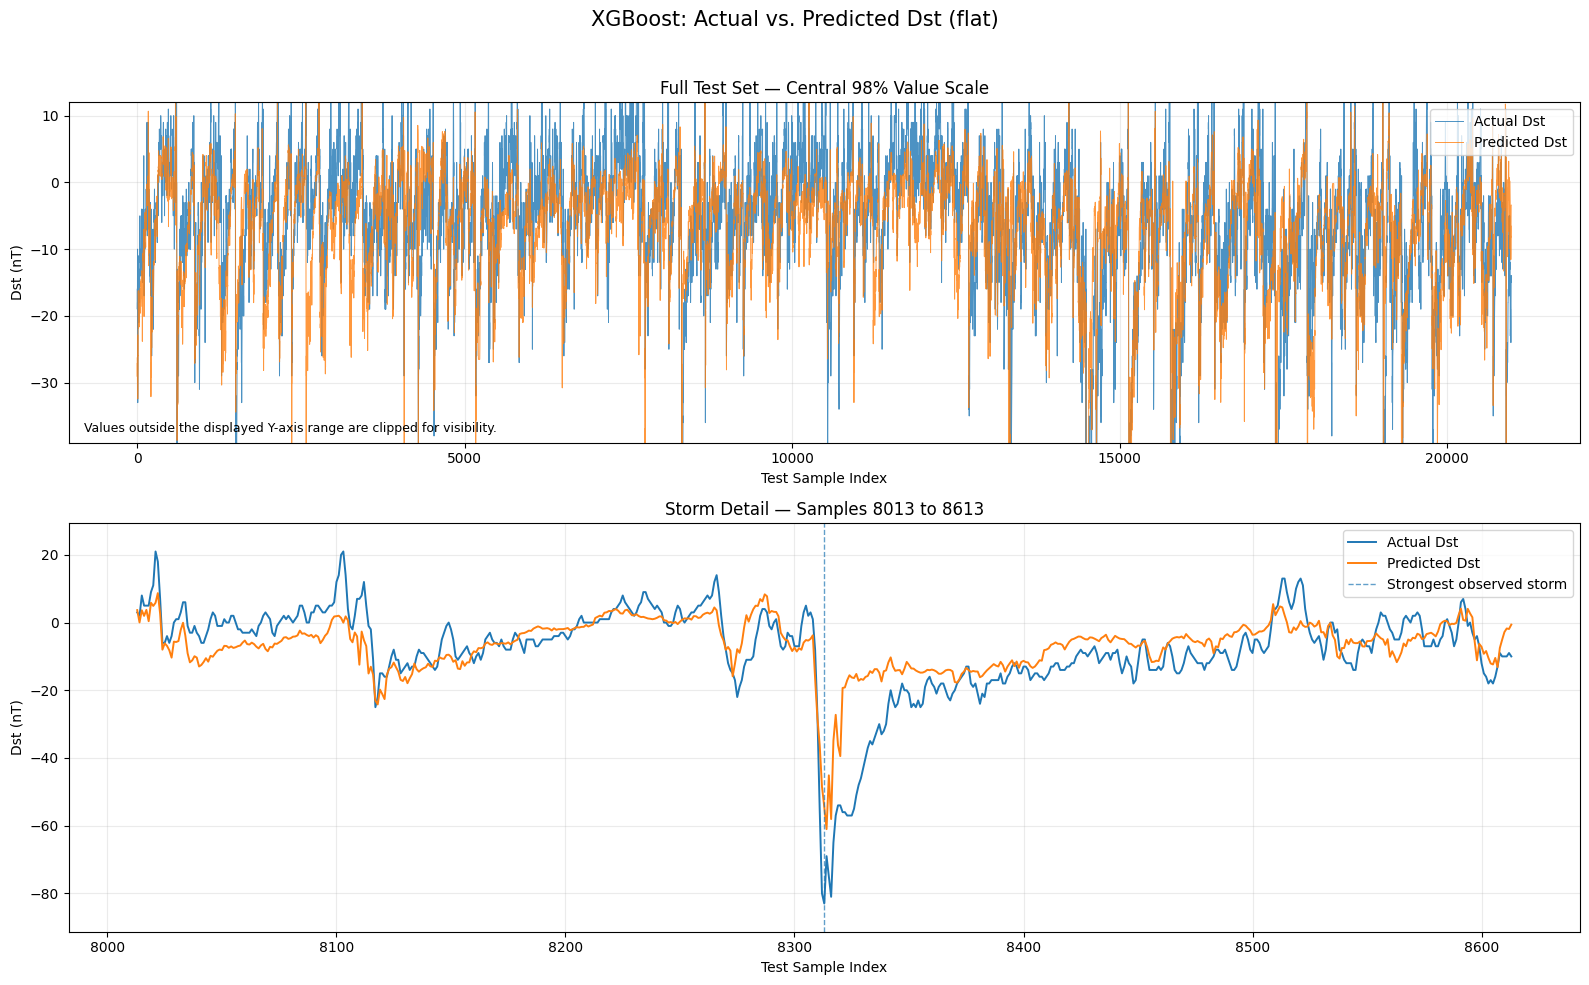

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_01_actual_vs_predicted_flat.png


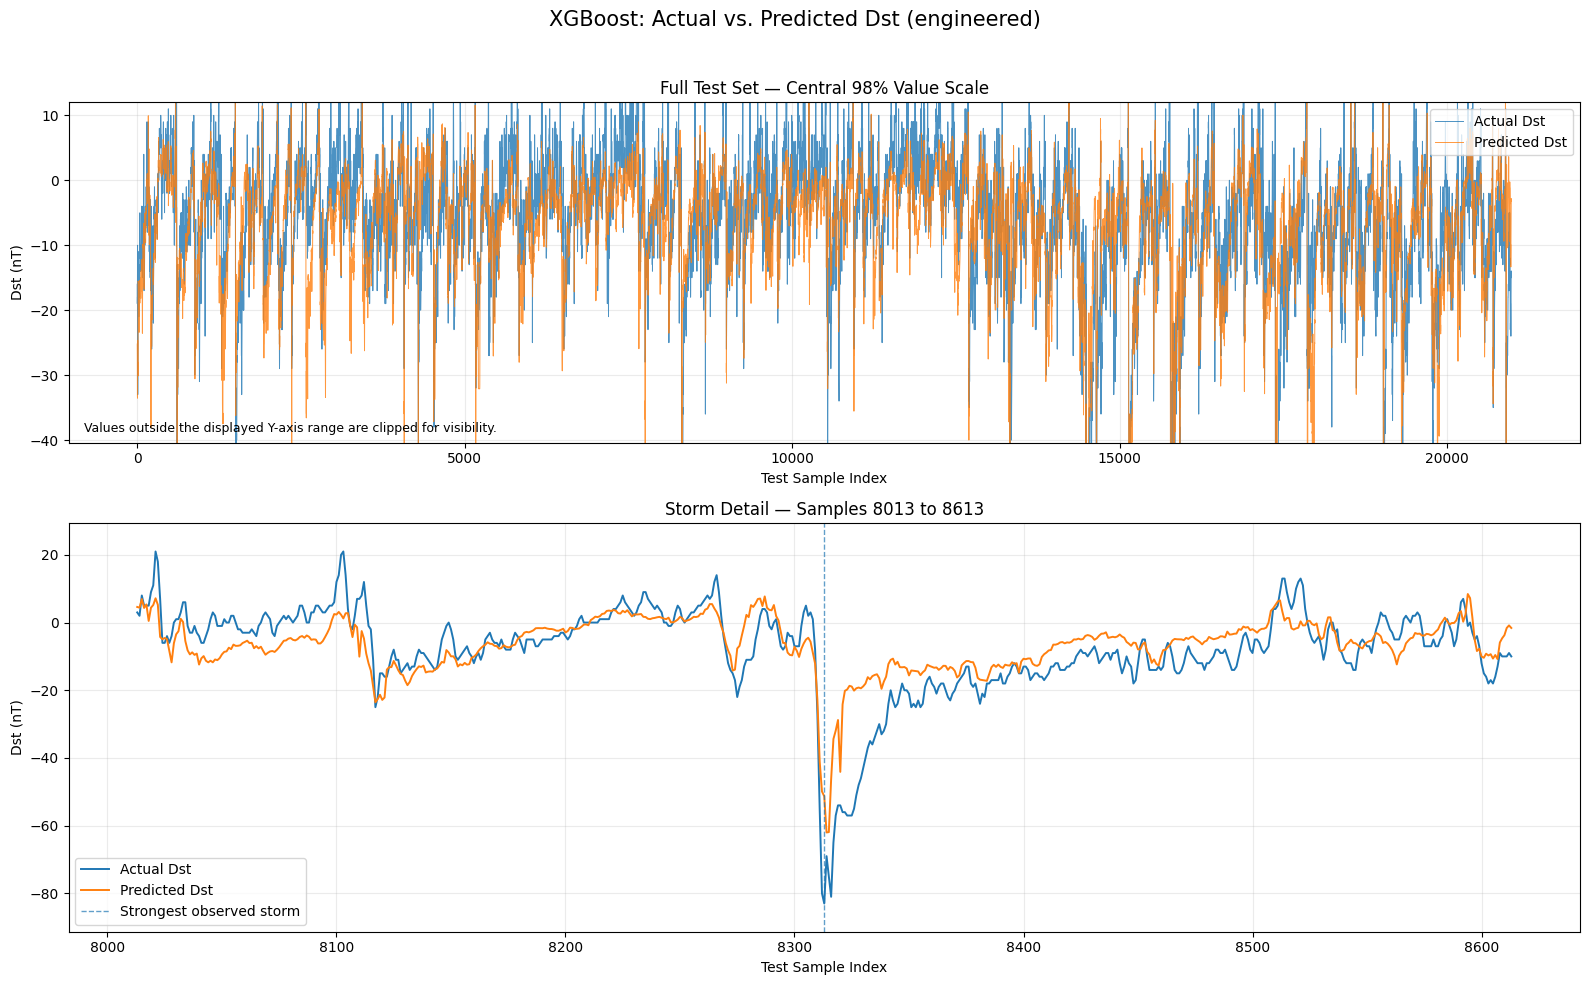

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_01_actual_vs_predicted_engineered.png


In [ ]:
# Cell 8: Improved Actual vs. Predicted Dst plots

def plot_actual_vs_predicted(y_true, y_pred, representation):

    # Find the strongest observed storm in the test set
    storm_index = int(np.argmin(y_true))

    # Zoom window: 300 samples before and after the strongest storm
    window = 300
    start = max(0, storm_index - window)
    end = min(len(y_true), storm_index + window + 1)

    indices = np.arange(len(y_true))
    zoom_indices = indices[start:end]

    # Use the central 98% of combined values for overview scaling
    combined = np.concatenate([y_true, y_pred])
    y_low, y_high = np.percentile(combined, [1, 99])

    # Create two vertically stacked views
    fig, axes = plt.subplots(
        2, 1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [1, 1.2]}
    )

    # --------------------------------------------------
    # Top: Full test-set overview
    # --------------------------------------------------
    axes[0].plot(
        indices, y_true,
        label="Actual Dst",
        linewidth=0.7,
        alpha=0.8
    )

    axes[0].plot(
        indices, y_pred,
        label="Predicted Dst",
        linewidth=0.7,
        alpha=0.8
    )

    axes[0].set_ylim(y_low, y_high)
    axes[0].set_title(
        "Full Test Set — Central 98% Value Scale"
    )
    axes[0].set_xlabel("Test Sample Index")
    axes[0].set_ylabel("Dst (nT)")
    axes[0].legend(loc="upper right")
    axes[0].grid(True, alpha=0.25)

    axes[0].text(
        0.01, 0.03,
        "Values outside the displayed Y-axis range are clipped for visibility.",
        transform=axes[0].transAxes,
        fontsize=9
    )

    # --------------------------------------------------
    # Bottom: Zoom around strongest observed storm
    # --------------------------------------------------
    actual_zoom = y_true[start:end]
    predicted_zoom = y_pred[start:end]

    axes[1].plot(
        zoom_indices, actual_zoom,
        label="Actual Dst",
        linewidth=1.4
    )

    axes[1].plot(
        zoom_indices, predicted_zoom,
        label="Predicted Dst",
        linewidth=1.4
    )

    # Automatically scale the zoom view to show all local values
    zoom_min = min(actual_zoom.min(), predicted_zoom.min())
    zoom_max = max(actual_zoom.max(), predicted_zoom.max())
    padding = max((zoom_max - zoom_min) * 0.08, 2)

    axes[1].set_ylim(
        zoom_min - padding,
        zoom_max + padding
    )

    axes[1].axvline(
        storm_index,
        linestyle="--",
        linewidth=1,
        alpha=0.7,
        label="Strongest observed storm"
    )

    axes[1].set_title(
        f"Storm Detail — Samples {start} to {end - 1}"
    )
    axes[1].set_xlabel("Test Sample Index")
    axes[1].set_ylabel("Dst (nT)")
    axes[1].legend(loc="best")
    axes[1].grid(True, alpha=0.25)

    fig.suptitle(
        f"XGBoost: Actual vs. Predicted Dst ({representation})",
        fontsize=15
    )

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    filename = (
        f"xgboost_01_actual_vs_predicted_{representation}.png"
    )
    save_path = os.path.join(FIGURES_PATH, filename)

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


# Generate both figures
plot_actual_vs_predicted(
    y_test_flat,
    xgb_flat_predictions,
    "flat"
)

plot_actual_vs_predicted(
    y_test_engineered,
    xgb_engineered_predictions,
    "engineered"
)

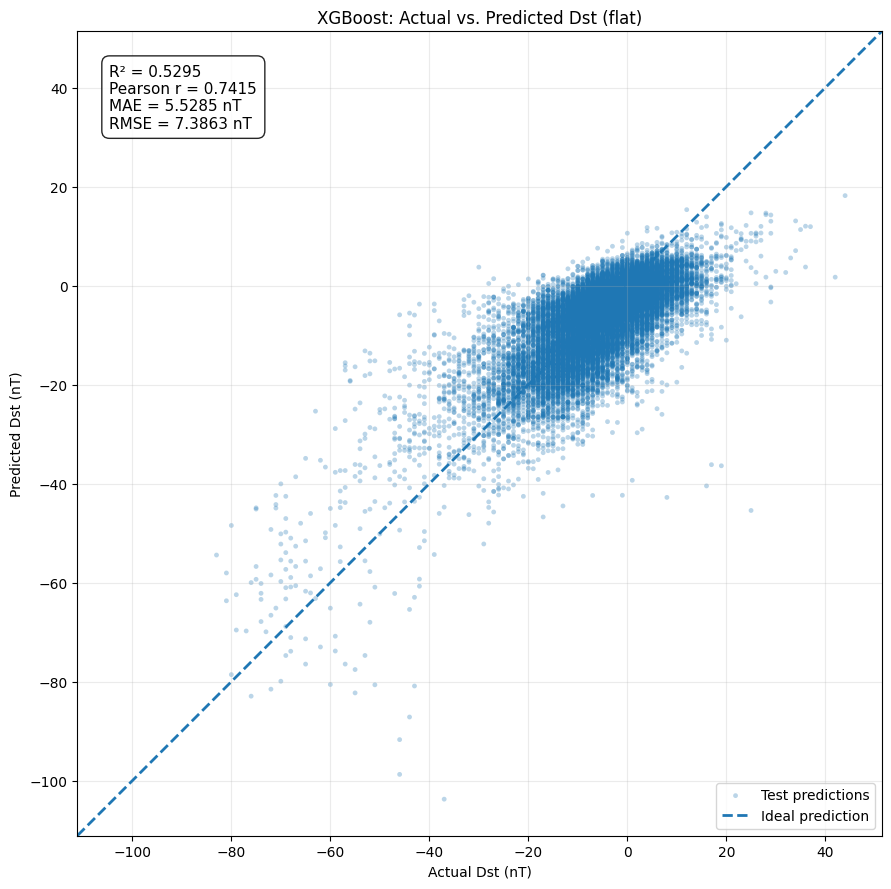

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_02_prediction_scatter_flat.png


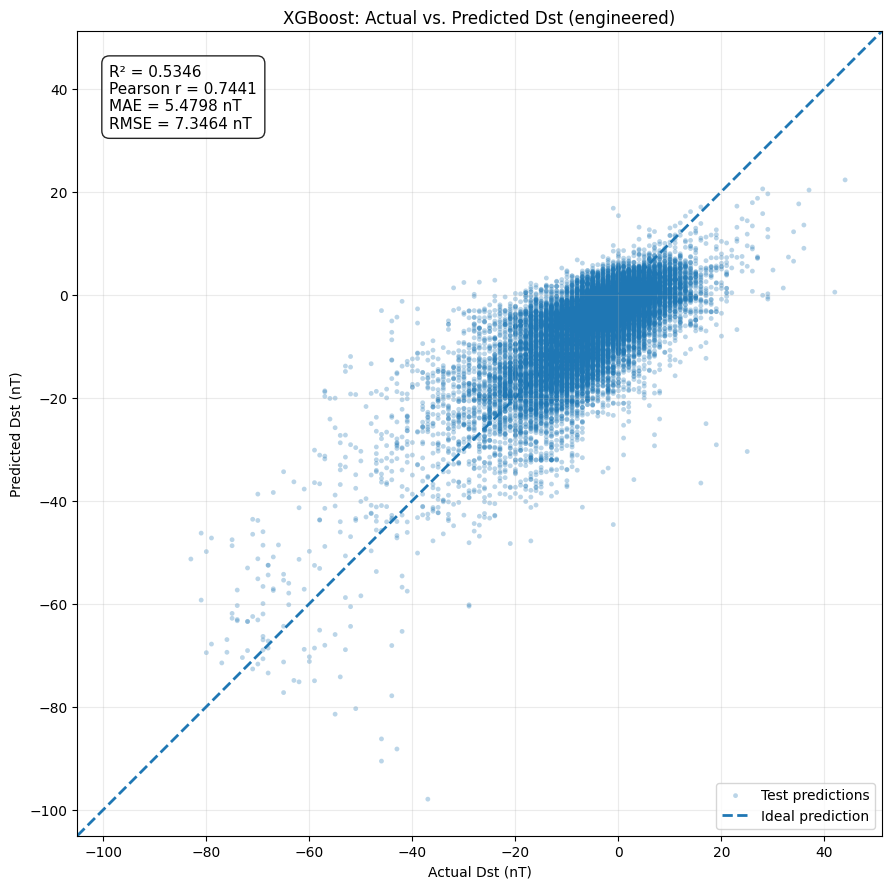

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_02_prediction_scatter_engineered.png


In [ ]:
# Cell 9: Prediction scatter plots with ideal line

def plot_prediction_scatter(y_true, y_pred, representation, metrics):

    fig, ax = plt.subplots(figsize=(9, 9))

    # Scatter plot
    ax.scatter(
        y_true,
        y_pred,
        s=12,
        alpha=0.3,
        edgecolors="none",
        label="Test predictions"
    )

    # Use identical limits for both axes
    lower = min(float(np.min(y_true)), float(np.min(y_pred)))
    upper = max(float(np.max(y_true)), float(np.max(y_pred)))
    padding = max((upper - lower) * 0.05, 2)

    axis_min = lower - padding
    axis_max = upper + padding

    # Ideal prediction line: predicted Dst = actual Dst
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        linestyle="--",
        linewidth=2,
        label="Ideal prediction"
    )

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"XGBoost: Actual vs. Predicted Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Predicted Dst (nT)")

    # Display key metrics
    annotation = (
        f"R² = {metrics['R2']:.4f}\n"
        f"Pearson r = {metrics['Pearson_Correlation']:.4f}\n"
        f"MAE = {metrics['MAE']:.4f} nT\n"
        f"RMSE = {metrics['RMSE']:.4f} nT"
    )

    ax.text(
        0.04, 0.96,
        annotation,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            alpha=0.85
        )
    )

    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()

    filename = f"xgboost_02_prediction_scatter_{representation}.png"
    save_path = os.path.join(FIGURES_PATH, filename)

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


# Flat-feature model
plot_prediction_scatter(
    y_test_flat,
    xgb_flat_predictions,
    "flat",
    xgb_flat_metrics
)

# Engineered-feature model
plot_prediction_scatter(
    y_test_engineered,
    xgb_engineered_predictions,
    "engineered",
    xgb_engineered_metrics
)

FLAT MODEL — RMSE BY DST INTENSITY


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,16.9425
1,"(-60, -40]",188,21.4484
2,"(-40, -20]",1441,10.9339
3,"(-20, 0]",13681,5.8807
4,> 0,5596,8.3665


ENGINEERED MODEL — RMSE BY DST INTENSITY


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,16.1815
1,"(-60, -40]",188,20.7079
2,"(-40, -20]",1441,11.2651
3,"(-20, 0]",13681,5.9484
4,> 0,5596,8.0822


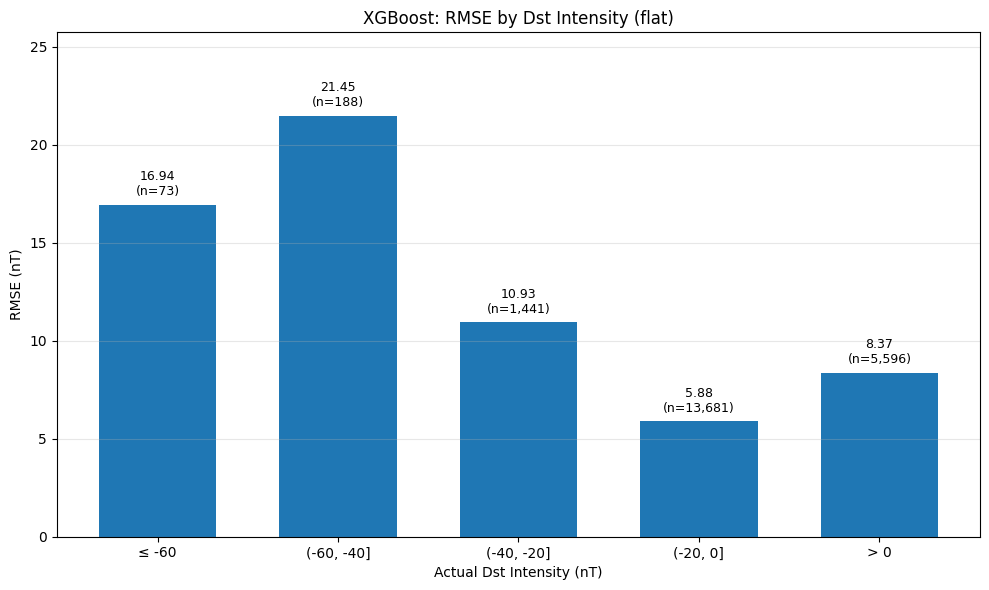

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_03_rmse_by_dst_intensity_flat.png


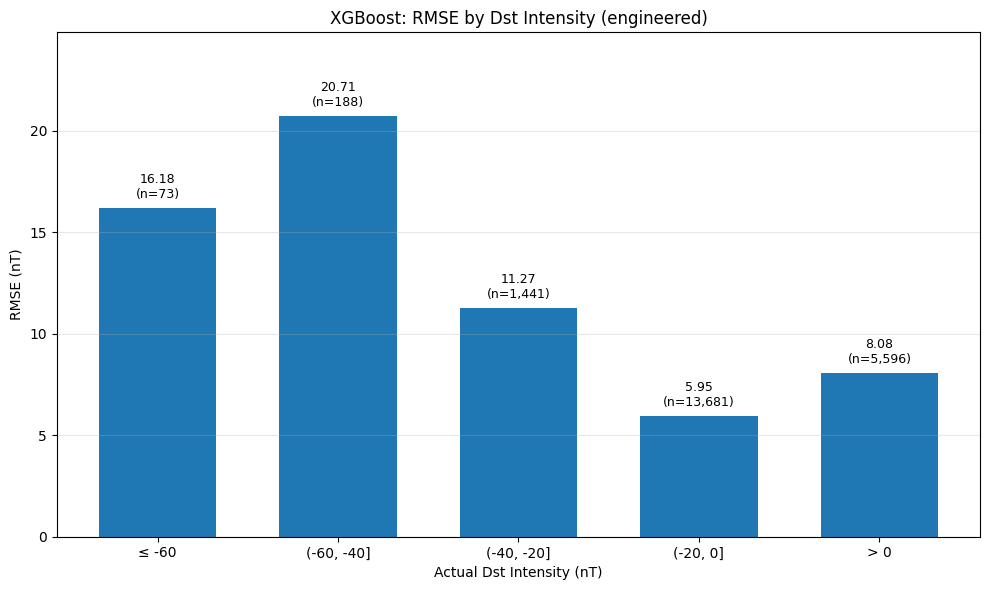

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_03_rmse_by_dst_intensity_engineered.png


In [ ]:
# Cell 10: RMSE by Dst intensity

DST_BINS = [
    ("≤ -60", lambda y: y <= -60),
    ("(-60, -40]", lambda y: (y > -60) & (y <= -40)),
    ("(-40, -20]", lambda y: (y > -40) & (y <= -20)),
    ("(-20, 0]", lambda y: (y > -20) & (y <= 0)),
    ("> 0", lambda y: y > 0)
]


def calculate_rmse_by_intensity(y_true, y_pred):
    results = []

    for label, condition in DST_BINS:
        mask = condition(y_true)
        sample_count = int(np.sum(mask))

        if sample_count == 0:
            rmse = np.nan
        else:
            rmse = float(
                np.sqrt(np.mean((y_true[mask] - y_pred[mask]) ** 2))
            )

        results.append({
            "dst_intensity_bin": label,
            "sample_count": sample_count,
            "RMSE": rmse
        })

    return pd.DataFrame(results)


# Calculate results for both representations
xgb_flat_intensity = calculate_rmse_by_intensity(
    y_test_flat,
    xgb_flat_predictions
)

xgb_engineered_intensity = calculate_rmse_by_intensity(
    y_test_engineered,
    xgb_engineered_predictions
)


def plot_rmse_by_intensity(results, representation):
    fig, ax = plt.subplots(figsize=(10, 6))

    labels = results["dst_intensity_bin"].tolist()
    values = results["RMSE"].to_numpy()
    counts = results["sample_count"].to_numpy()

    bars = ax.bar(labels, values, width=0.65)

    ax.set_title(
        f"XGBoost: RMSE by Dst Intensity ({representation})"
    )
    ax.set_xlabel("Actual Dst Intensity (nT)")
    ax.set_ylabel("RMSE (nT)")
    ax.grid(axis="y", alpha=0.3)

    # Display RMSE and sample count on each bar
    for bar, value, count in zip(bars, values, counts):
        if np.isfinite(value):
            ax.annotate(
                f"{value:.2f}\n(n={count:,})",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )
        else:
            ax.annotate(
                f"No samples\n(n={count:,})",
                xy=(bar.get_x() + bar.get_width() / 2, 0),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_ylim(
        0,
        np.nanmax(values) * 1.2 if np.isfinite(values).any() else 1
    )
    fig.tight_layout()

    filename = (
        f"xgboost_03_rmse_by_dst_intensity_{representation}.png"
    )
    save_path = os.path.join(FIGURES_PATH, filename)

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


# Display numerical results
print("FLAT MODEL — RMSE BY DST INTENSITY")
display(xgb_flat_intensity.round(4))

print("ENGINEERED MODEL — RMSE BY DST INTENSITY")
display(xgb_engineered_intensity.round(4))


# Save both figures
plot_rmse_by_intensity(xgb_flat_intensity, "flat")
plot_rmse_by_intensity(xgb_engineered_intensity, "engineered")

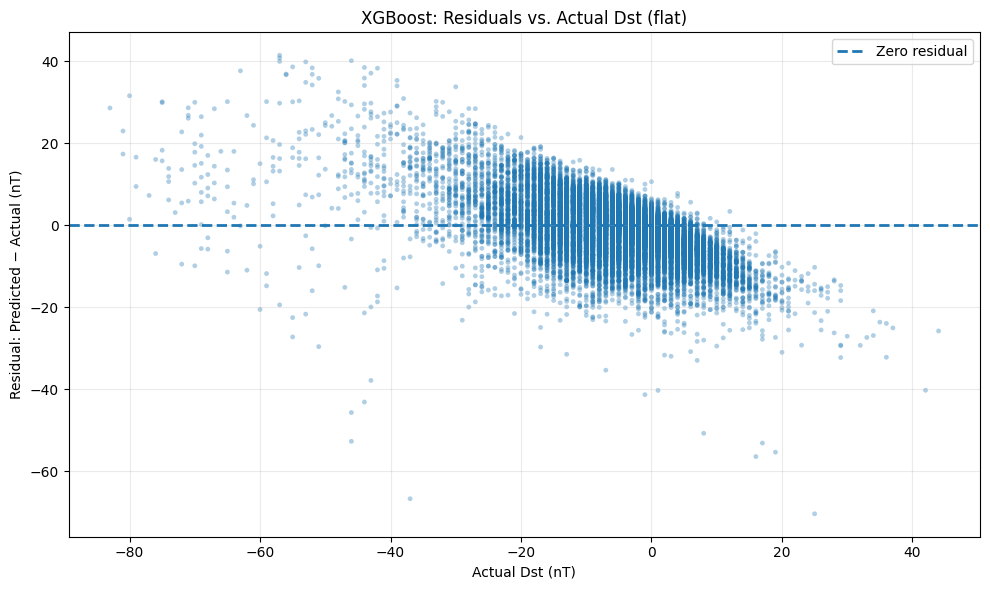

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_04_residuals_vs_actual_flat.png
Mean residual: -1.2486 nT
Residual standard deviation: 7.2800 nT


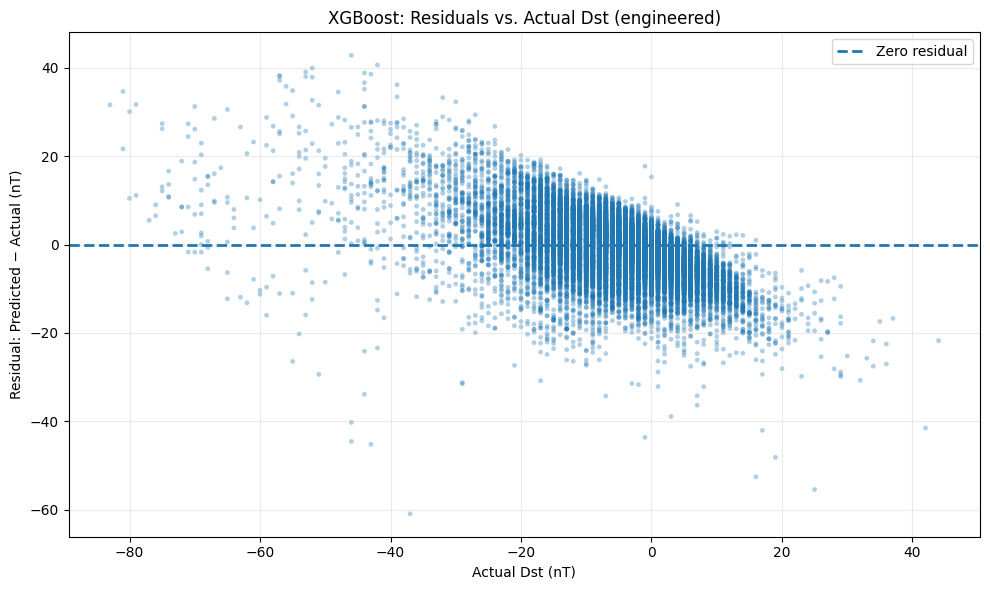

Figure saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting/xgboost_04_residuals_vs_actual_engineered.png
Mean residual: -1.0424 nT
Residual standard deviation: 7.2721 nT


In [ ]:
# Cell 11: Residuals vs. actual Dst

def plot_residuals(y_true, y_pred, representation):
    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        y_true,
        residuals,
        s=12,
        alpha=0.35,
        edgecolors="none"
    )

    # Ideal residual level
    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=2,
        label="Zero residual"
    )

    ax.set_title(
        f"XGBoost: Residuals vs. Actual Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Residual: Predicted − Actual (nT)")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

    filename = f"xgboost_04_residuals_vs_actual_{representation}.png"
    save_path = os.path.join(FIGURES_PATH, filename)

    fig.savefig(
        save_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)
    print(f"Mean residual: {np.mean(residuals):.4f} nT")
    print(f"Residual standard deviation: {np.std(residuals):.4f} nT")


# Flat-feature model
plot_residuals(
    y_test_flat,
    xgb_flat_predictions,
    "flat"
)

# Engineered-feature model
plot_residuals(
    y_test_engineered,
    xgb_engineered_predictions,
    "engineered"
)

In [ ]:
# Cell 12: Save and verify the complete XGBoost experiment

from datetime import datetime, timezone

# --------------------------------------------------
# 1. Save validation and test predictions
# --------------------------------------------------

prediction_arrays = {
    "xgboost_flat_validation_predictions.npy":
        flat_model.predict(X_val_flat),
    "xgboost_engineered_validation_predictions.npy":
        engineered_model.predict(X_val_engineered),
    "xgboost_flat_predictions.npy":
        xgb_flat_predictions,
    "xgboost_engineered_predictions.npy":
        xgb_engineered_predictions
}

for filename, predictions in prediction_arrays.items():
    np.save(
        os.path.join(RESULTS_PATH, filename),
        np.asarray(predictions, dtype=np.float32)
    )

print("Validation and test predictions saved.")


# --------------------------------------------------
# 2. Record model sizes
# --------------------------------------------------

model_paths = {
    "flat": FLAT_MODEL_PATH,
    "engineered": ENGINEERED_MODEL_PATH
}

model_sizes = {}

for name, path in model_paths.items():
    size_bytes = os.path.getsize(path)

    model_sizes[name] = {
        "model_size_bytes": int(size_bytes),
        "model_size_MB": float(size_bytes / (1024 ** 2))
    }


# --------------------------------------------------
# 3. Combine metrics and performance measurements
# --------------------------------------------------

model_runs = [
    (
        "flat",
        xgb_flat_metrics,
        xgb_flat_training_time,
        xgb_flat_timing,
        flat_model,
        X_train_flat.shape[1],
        xgb_flat_training_history
    ),
    (
        "engineered",
        xgb_engineered_metrics,
        xgb_engineered_training_time,
        xgb_engineered_timing,
        engineered_model,
        X_train_engineered.shape[1],
        xgb_engineered_training_history
    )
]

comparison_rows = []

for (
    representation,
    metrics,
    training_time,
    timing,
    model,
    n_features,
    history
) in model_runs:

    row = {
        "model": "XGBoost",
        "representation": representation,
        **metrics,
        "training_time_seconds": float(training_time),
        "final_training_RMSE": float(
            history["train_rmse"].iloc[-1]
        ),
        "final_validation_RMSE": float(
            history["validation_rmse"].iloc[-1]
        ),
        "inference_time_seconds": float(
            timing["mean_inference_time_seconds"]
        ),
        "inference_time_std_seconds": float(
            timing["std_inference_time_seconds"]
        ),
        "latency_ms_per_sample": float(
            timing["mean_latency_ms_per_sample"]
        ),
        "throughput_samples_per_second": float(
            timing["throughput_samples_per_second"]
        ),
        "model_size_bytes": model_sizes[representation][
            "model_size_bytes"
        ],
        "model_size_MB": model_sizes[representation]["model_size_MB"],
        "n_features": int(n_features),
        "n_estimators": int(model.n_estimators),
        "max_depth": int(XGB_PARAMS["max_depth"]),
        "learning_rate": float(XGB_PARAMS["learning_rate"]),
        "n_train_samples": int(len(y_train_flat)),
        "n_validation_samples": int(len(y_val_flat)),
        "n_test_samples": int(len(y_test_flat))
    }

    comparison_rows.append(row)

xgboost_comparison_df = pd.DataFrame(comparison_rows)


# --------------------------------------------------
# 4. Save metrics as JSON and CSV
# --------------------------------------------------

metrics_output = {
    "model": "XGBoost",
    "experiment": "Geomagnetic Dst forecasting",
    "target_unit": "nT",
    "evaluation_split": "test",
    "flat": comparison_rows[0],
    "engineered": comparison_rows[1]
}

METRICS_JSON_PATH = os.path.join(
    RESULTS_PATH, "xgboost_metrics.json"
)

METRICS_CSV_PATH = os.path.join(
    RESULTS_PATH, "xgboost_metrics.csv"
)

with open(METRICS_JSON_PATH, "w") as f:
    json.dump(metrics_output, f, indent=4, allow_nan=False)

xgboost_comparison_df.to_csv(
    METRICS_CSV_PATH,
    index=False
)

print("Metrics JSON and CSV saved.")


# --------------------------------------------------
# 5. Save Dst intensity results
# --------------------------------------------------

flat_intensity = xgb_flat_intensity.copy()
flat_intensity["representation"] = "flat"

engineered_intensity = xgb_engineered_intensity.copy()
engineered_intensity["representation"] = "engineered"

intensity_results = pd.concat(
    [flat_intensity, engineered_intensity],
    ignore_index=True
)

intensity_results.insert(0, "model", "XGBoost")

INTENSITY_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_rmse_by_dst_intensity.csv"
)

intensity_results.to_csv(
    INTENSITY_PATH,
    index=False
)

print("Dst intensity results saved.")


# --------------------------------------------------
# 6. Save experiment metadata
# --------------------------------------------------

run_metadata = {
    "model": "XGBoost",
    "experiment": "Geomagnetic Dst forecasting",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": int(SEED),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "xgboost_version": xgb.__version__,
    "training_device": XGB_PARAMS["device"],
    "parameters": XGB_PARAMS,
    "training_protocol": {
        "boosting_rounds": int(XGB_PARAMS["n_estimators"]),
        "early_stopping": False,
        "validation_used_for_monitoring": True,
        "test_used_for_final_evaluation": True
    },
    "data_shapes": {
        "flat_train": list(X_train_flat.shape),
        "flat_validation": list(X_val_flat.shape),
        "flat_test": list(X_test_flat.shape),
        "engineered_train": list(X_train_engineered.shape),
        "engineered_validation": list(X_val_engineered.shape),
        "engineered_test": list(X_test_engineered.shape)
    },
    "model_files": model_paths,
    "model_sizes": model_sizes
}

METADATA_PATH = os.path.join(
    RESULTS_PATH,
    "xgboost_run_metadata.json"
)

with open(METADATA_PATH, "w") as f:
    json.dump(run_metadata, f, indent=4, allow_nan=False)

print("Run metadata saved.")


# --------------------------------------------------
# 7. Verify saved files and figures
# --------------------------------------------------

expected_files = [
    "xgboost_parameters.json",
    "xgboost_flat_model.json",
    "xgboost_engineered_model.json",
    "xgboost_flat_training_history.csv",
    "xgboost_engineered_training_history.csv",
    "xgboost_inference_timing.json",
    "xgboost_flat_validation_predictions.npy",
    "xgboost_engineered_validation_predictions.npy",
    "xgboost_flat_predictions.npy",
    "xgboost_engineered_predictions.npy",
    "xgboost_metrics.json",
    "xgboost_metrics.csv",
    "xgboost_rmse_by_dst_intensity.csv",
    "xgboost_run_metadata.json"
]

expected_figures = [
    f"xgboost_01_actual_vs_predicted_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"xgboost_02_prediction_scatter_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"xgboost_03_rmse_by_dst_intensity_{rep}.png"
    for rep in ("flat", "engineered")
] + [
    f"xgboost_04_residuals_vs_actual_{rep}.png"
    for rep in ("flat", "engineered")
]

missing_files = [
    name for name in expected_files
    if not os.path.isfile(os.path.join(RESULTS_PATH, name))
]

missing_figures = [
    name for name in expected_figures
    if not os.path.isfile(os.path.join(FIGURES_PATH, name))
]

print("\nFINAL XGBOOST COMPARISON")

display(
    xgboost_comparison_df[
        [
            "model",
            "representation",
            "MAE",
            "RMSE",
            "R2",
            "Pearson_Correlation",
            "training_time_seconds",
            "latency_ms_per_sample",
            "throughput_samples_per_second",
            "model_size_MB"
        ]
    ].round(4)
)

print("\nOutput directory:", RESULTS_PATH)
print(
    f"Required files verified: "
    f"{len(expected_files) - len(missing_files)}/{len(expected_files)}"
)
print(
    f"Figures verified: "
    f"{len(expected_figures) - len(missing_figures)}/{len(expected_figures)}"
)

if missing_files:
    print("Missing files:", missing_files)

if missing_figures:
    print("Missing figures:", missing_figures)

assert not missing_files, "Some required result files are missing."
assert not missing_figures, "Some required figures are missing."

print("\nXGBOOST EXPERIMENT COMPLETED AND VERIFIED.")

Validation and test predictions saved.
Metrics JSON and CSV saved.
Dst intensity results saved.
Run metadata saved.

FINAL XGBOOST COMPARISON


,model,representation,MAE,RMSE,R2,Pearson_Correlation,training_time_seconds,latency_ms_per_sample,throughput_samples_per_second,model_size_MB
0,XGBoost,flat,5.5285,7.3863,0.5295,0.7415,204.7794,0.0094,106552.7677,1.9021
1,XGBoost,engineered,5.4798,7.3464,0.5346,0.7441,17.0552,0.0028,363259.2436,1.9195



Output directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Boosting
Required files verified: 14/14
Figures verified: 8/8

XGBOOST EXPERIMENT COMPLETED AND VERIFIED.
